In [13]:
from pathlib import Path
import json, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from IPython.display import display

jax.config.update("jax_enable_x64", True)
ROOT = Path("policy_uncertainty_outputs")
FIG = ROOT / "figures"
TAB = ROOT / "reports"
for folder in (FIG, TAB): folder.mkdir(parents=True, exist_ok=True)
SEED = 20261107
H, GAMMA, S, A = 8, 0.97, 5, 2

## Reference model

The transition and reward model stays fixed.

Exact dynamic programming gives the reference policy values.

In [2]:
# Transition probabilities P[state, action, next_state].
P = np.zeros((S,A,S))
for s in range(S):
    for a in range(A):
        center = np.clip(s + (1 if a == 0 else -1), 0, S-1)
        P[s,a,center] += .70
        P[s,a,s] += .20
        P[s,a,np.clip(center + (1 if a == 0 else -1),0,S-1)] += .10
assert np.allclose(P.sum(axis=2), 1)
# Reward is negative operating cost. A higher value is better.
R = np.array([[-(0.3*s + 0.15*s*s + .3), -(0.3*s + 0.15*s*s + .85)] for s in range(S)])
INIT = np.array([.30,.25,.20,.15,.10])
behavior = np.column_stack([np.linspace(.68,.42,S), np.linspace(.32,.58,S)])
target = np.column_stack([np.linspace(.50,.20,S), np.linspace(.50,.80,S)])

def exact_value(policy):
    p = jnp.asarray(P); r = jnp.asarray(R); pi = jnp.asarray(policy)
    v = jnp.zeros(S)
    for _ in range(H):
        q = r + GAMMA*jnp.einsum('sak,k->sa',p,v)
        v = jnp.sum(pi*q,axis=1)
    return float(jnp.asarray(INIT) @ v)

TRUTH = exact_value(target)
print('Exact target policy value:', round(TRUTH,5))
print('Exact behavior policy value:', round(exact_value(behavior),5))

Exact target policy value: -11.0527
Exact behavior policy value: -14.00201


## Historical data

Trajectories are sampled under the logging policy.

Each experiment uses a fresh random seed.

In [3]:
def simulate(n, pi, seed, noise=1.0):
    rng=np.random.default_rng(seed)
    states=np.empty((n,H+1),dtype=np.int32)
    actions=np.empty((n,H),dtype=np.int32)
    rewards=np.empty((n,H))
    states[:,0]=rng.choice(S,size=n,p=INIT)
    for t in range(H):
        s=states[:,t]
        a=(rng.random(n)>pi[s,0]).astype(np.int32)
        actions[:,t]=a
        rewards[:,t]=R[s,a]+rng.normal(0,noise,n)
        u=rng.random(n)
        cdf=np.cumsum(P[s,a,:],axis=1)
        states[:,t+1]=(u[:,None]>cdf).sum(axis=1).astype(np.int32)
    return states,actions,rewards

s,a,r=simulate(1500,behavior,SEED)
print('Episodes:',len(s),'| action frequencies:',np.bincount(a.ravel())/a.size)
print('Observed discounted reward:',np.mean(np.sum(r*GAMMA**np.arange(H),axis=1)))

Episodes: 1500 | action frequencies: [0.55608333 0.44391667]
Observed discounted reward: -13.886904467358043


## Cross-fitted evaluation

Action values are fitted on separate episodes.

Held-out contributions are used for the uncertainty calculations.

In [4]:
def fit_q(states, actions, rewards, target_pi, ridge=0.5):
    # Independent, time-indexed fitted Q evaluation, with pooled state-action cells.
    n=len(states)
    q=np.zeros((H,S,A)); vnext=np.zeros(S)
    for t in range(H-1,-1,-1):
        y=rewards[:,t]+GAMMA*vnext[states[:,t+1]]
        for st in range(S):
            for act in range(A):
                m=(states[:,t]==st)&(actions[:,t]==act)
                # Shrink toward the pooled reward-to-go mean to stabilize sparse cells.
                q[t,st,act]=(y[m].sum()+ridge*y.mean())/(m.sum()+ridge)
        vnext=np.sum(target_pi*q[t],axis=1)
    return q

def contributions(states,actions,rewards,bpi,tpi,q):
    n=len(states); w=np.ones(n); pd=np.zeros(n); dr=np.zeros(n)
    v=np.einsum('sa,tsa->ts',tpi,q)
    dr[:]=v[0,states[:,0]]
    for t in range(H):
        st=states[:,t]; act=actions[:,t]
        w *= tpi[st,act]/bpi[st,act]
        pd += GAMMA**t*w*rewards[:,t]
        vnext=v[t+1,states[:,t+1]] if t+1<H else np.zeros(n)
        dr += GAMMA**t*w*(rewards[:,t]+GAMMA*vnext-q[t,st,act])
    return pd,dr,w

def estimate(states,actions,rewards,bpi,tpi,folds=2):
    n=len(states); rng=np.random.default_rng(2718+n)
    perm=rng.permutation(n); groups=np.array_split(perm,folds)
    dm=np.empty(n); pd=np.empty(n); dr=np.empty(n); terminal_w=np.empty(n)
    for group in groups:
        train=np.setdiff1d(np.arange(n),group,assume_unique=True)
        q=fit_q(states[train],actions[train],rewards[train],tpi)
        dm[group]=np.sum(tpi[states[group,0]]*q[0,states[group,0]],axis=1)
        pd[group],dr[group],terminal_w[group]=contributions(states[group],actions[group],rewards[group],bpi,tpi,q)
    return {'Direct':dm,'PDIS':pd,'DR':dr},terminal_w

def summary(contrib,truth):
    x=np.asarray(contrib); est=x.mean(); se=x.std(ddof=1)/np.sqrt(len(x))
    return {'estimate':est,'se':se,'lower':est-1.96*se,'upper':est+1.96*se,
            'error':est-truth,'covered':float(abs(est-truth)<=1.96*se)}

parts,weights=estimate(s,a,r,behavior,target)
print(pd.DataFrame({k:summary(v,TRUTH) for k,v in parts.items()}).T.round(4))

        estimate      se    lower    upper   error  covered
Direct  -10.9542  0.0887 -11.1282 -10.7803  0.0985      1.0
PDIS    -10.7571  0.2039 -11.1567 -10.3574  0.2956      1.0
DR      -10.8576  0.1389 -11.1299 -10.5853  0.1951      1.0


## Interval methods

We compare normal intervals with a bootstrap interval based on episode-level contributions.

The bootstrap treats fitted nuisance models as fixed. Its coverage is checked empirically rather than assumed.

In [5]:
def intervals(x, rng, draws=400):
    x=np.asarray(x,float); n=len(x); mean=x.mean()
    se=x.std(ddof=1)/np.sqrt(n)
    normal=(mean-1.96*se,mean+1.96*se)
    indices=rng.integers(0,n,size=(draws,n))
    boot=x[indices].mean(axis=1)
    percentile=tuple(np.quantile(boot,[.025,.975]))
    return {"normal":normal,"bootstrap":percentile}

def ess_fraction(weights):
    weights=np.asarray(weights,float)
    return float(weights.sum()**2/(len(weights)*np.sum(weights**2)+1e-15))

scenarios={
    "near behavior":(behavior,.8*behavior+.2*target),
    "moderate overlap":(behavior,target),
    "limited overlap":(
        np.column_stack([np.linspace(.97,.91,S),np.linspace(.03,.09,S)]),target)
}
print("Scenarios:",", ".join(scenarios))


Scenarios: near behavior, moderate overlap, limited overlap


## Repeated experiments

We repeat each setting using independent logged datasets.

The policy value is compared with exact ground truth for every repetition.

In [6]:
REPS=35
N=800
records=[]
start=time.time()
for si,(name,(bpi,tpi)) in enumerate(scenarios.items()):
    truth=exact_value(tpi)
    for rep in range(REPS):
        rng=np.random.default_rng(SEED+100000*si+rep)
        st,ac,rw=simulate(N,bpi,SEED+100000*si+rep)
        parts,weights=estimate(st,ac,rw,bpi,tpi,folds=3)
        support=ess_fraction(weights)
        for method,values in parts.items():
            ci=intervals(values,rng)
            for interval_type,(lo,hi) in ci.items():
                records.append({"scenario":name,"rep":rep,"method":method,
                    "interval":interval_type,"truth":truth,
                    "estimate":float(np.mean(values)),
                    "error":float(np.mean(values)-truth),
                    "lower":float(lo),"upper":float(hi),
                    "covered":int(lo<=truth<=hi),
                    "width":float(hi-lo),"terminal_ess_fraction":support})
results=pd.DataFrame(records)
results.to_csv(TAB/"repeated_intervals.csv",index=False)
print("Independent datasets:",len(scenarios)*REPS,"| evaluations:",len(results))
print("Elapsed seconds:",round(time.time()-start,1))
display(results.head().round(4))


Independent datasets: 105 | evaluations: 630
Elapsed seconds: 1.3


,scenario,rep,method,interval,truth,estimate,error,lower,upper,covered,width,terminal_ess_fraction
0,near behavior,0,Direct,normal,-13.3573,-13.3824,-0.0251,-13.6511,-13.1137,1,0.5374,0.9511
1,near behavior,0,Direct,bootstrap,-13.3573,-13.3824,-0.0251,-13.6168,-13.1461,1,0.4706,0.9511
2,near behavior,0,PDIS,normal,-13.3573,-13.4394,-0.0822,-13.8446,-13.0343,1,0.8103,0.9511
3,near behavior,0,PDIS,bootstrap,-13.3573,-13.4394,-0.0822,-13.8589,-13.0462,1,0.8127,0.9511
4,near behavior,0,DR,normal,-13.3573,-13.4017,-0.0444,-13.7885,-13.0148,1,0.7736,0.9511


## Accuracy and coverage

Bias and RMSE are measured against the exact values.

Coverage and interval width are reported together.

,scenario,method,interval,bias,rmse,coverage,interval_width,median_terminal_ess_fraction
0,near behavior,Direct,normal,-0.0203,0.1675,0.8857,0.5457,0.9490
1,near behavior,Direct,bootstrap,-0.0203,0.1675,0.8857,0.5374,0.9490
2,near behavior,PDIS,normal,-0.0068,0.1780,1.0000,0.8170,0.9490
3,near behavior,PDIS,bootstrap,-0.0068,0.1780,1.0000,0.7993,0.9490
4,near behavior,DR,normal,-0.0133,0.1589,1.0000,0.7708,0.9490
5,near behavior,DR,bootstrap,-0.0133,0.1589,1.0000,0.7673,0.9490
6,moderate overlap,Direct,normal,-0.1052,0.2131,0.6571,0.4765,0.3312
7,moderate overlap,Direct,bootstrap,-0.1052,0.2131,0.6857,0.4710,0.3312
8,moderate overlap,PDIS,normal,-0.0650,0.2523,1.0000,1.1547,0.3312
9,moderate overlap,PDIS,bootstrap,-0.0650,0.2523,0.9714,1.1452,0.3312


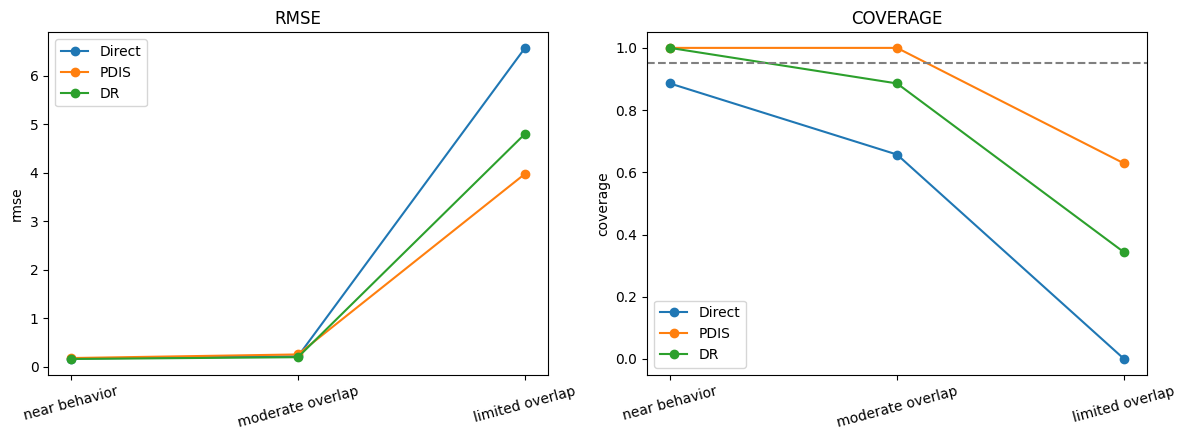

In [7]:
def summarize(g):
    return pd.Series({"bias":g.error.mean(),
      "rmse":np.sqrt(np.mean(g.error**2)),
      "coverage":g.covered.mean(),
      "interval_width":g.width.mean(),
      "median_terminal_ess_fraction":g.terminal_ess_fraction.median()})
metrics=results.groupby(["scenario","method","interval"],sort=False).apply(
    summarize,include_groups=False).reset_index()
metrics.to_csv(TAB/"accuracy_coverage.csv",index=False)
display(metrics.round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,metric in zip(axes,["rmse","coverage"]):
    for method in ["Direct","PDIS","DR"]:
        d=metrics[(metrics.method==method)&(metrics.interval=="normal")]
        ax.plot(d.scenario,d[metric],marker="o",label=method)
    if metric=="coverage":ax.axhline(.95,linestyle="--",color="gray")
    ax.set(title=metric.upper(),ylabel=metric)
    ax.tick_params(axis="x",rotation=15)
    ax.legend()
fig.tight_layout();fig.savefig(FIG/"accuracy_and_coverage.png",dpi=160);plt.show()


## Interval comparison

The normal and bootstrap intervals are checked on the same datasets.

We also record the uncertainty in the measured coverage rate.

,scenario,method,interval,coverage,wilson_low,wilson_high,mean_width
0,limited overlap,DR,bootstrap,0.371,0.232,0.537,7.489
1,limited overlap,DR,normal,0.343,0.208,0.508,8.207
6,moderate overlap,DR,bootstrap,0.886,0.740,0.955,0.783
7,moderate overlap,DR,normal,0.886,0.740,0.955,0.784
12,near behavior,DR,bootstrap,1.000,0.901,1.000,0.767
13,near behavior,DR,normal,1.000,0.901,1.000,0.771


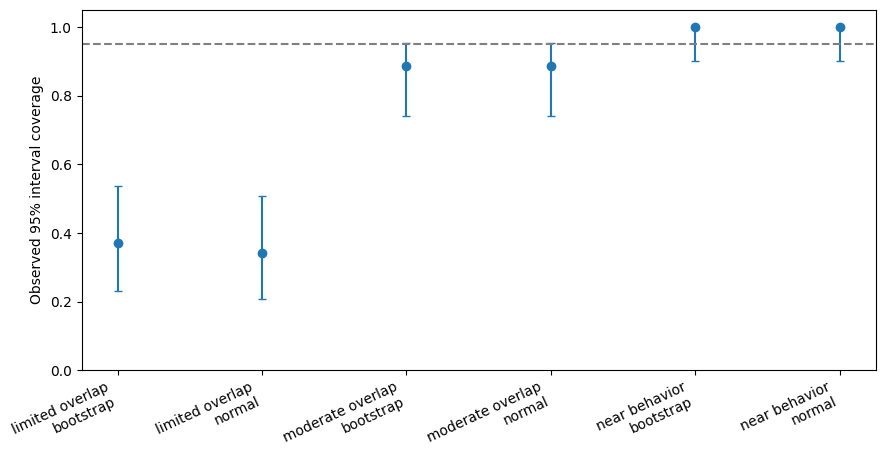

In [8]:
def wilson(k,n,z=1.96):
    p=k/n; den=1+z*z/n
    mid=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return mid-half,mid+half
coverage=[]
for (scenario,method,interval),g in results.groupby(["scenario","method","interval"]):
    lo,hi=wilson(int(g.covered.sum()),len(g))
    coverage.append({"scenario":scenario,"method":method,"interval":interval,
                     "coverage":g.covered.mean(),"wilson_low":lo,"wilson_high":hi,
                     "mean_width":g.width.mean()})
coverage=pd.DataFrame(coverage)
coverage.to_csv(TAB/"coverage_wilson.csv",index=False)
display(coverage[coverage.method=="DR"].round(3))
fig,ax=plt.subplots(figsize=(9,4.8))
sub=coverage[coverage.method=="DR"]
x=np.arange(len(sub))
ax.errorbar(x,sub.coverage,yerr=[sub.coverage-sub.wilson_low,
            sub.wilson_high-sub.coverage],fmt="o",capsize=3)
ax.axhline(.95,linestyle="--",color="gray")
ax.set(xticks=x,xticklabels=[f"{a}\n{b}" for a,b in zip(sub.scenario,sub.interval)],
       ylabel="Observed 95% interval coverage",ylim=(0,1.05))
plt.setp(ax.get_xticklabels(),rotation=25,ha="right")
fig.tight_layout();fig.savefig(FIG/"interval_calibration.png",dpi=160);plt.show()


## Logging probability sensitivity

The true action probabilities are known in the simulation.

We perturb the probabilities used for evaluation and measure the resulting estimation error.

,shift,method,bias,rmse
0,0.00,DR,0.0180,0.2210
1,0.00,PDIS,0.0585,0.2979
2,0.03,DR,0.0652,0.2477
3,0.03,PDIS,-0.9676,1.0354
4,0.07,DR,0.1691,0.3608
5,0.07,PDIS,-3.3804,3.4299
6,0.12,DR,0.4540,0.9299
7,0.12,PDIS,-10.0234,10.1361


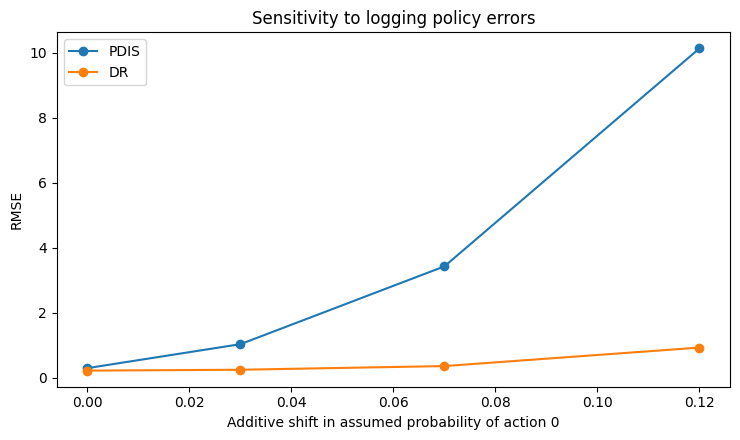

In [9]:
SENS_REPS=40
shifts=[0.0,.03,.07,.12]
sensitivity=[]
bpi,tpi=scenarios["moderate overlap"]
truth=exact_value(tpi)
for rep in range(SENS_REPS):
    st,ac,rw=simulate(N,bpi,SEED+300000+rep)
    for shift in shifts:
        assumed=np.clip(bpi[:,0]+shift,.02,.98)
        b_assumed=np.column_stack([assumed,1-assumed])
        parts,_=estimate(st,ac,rw,b_assumed,tpi,folds=3)
        for method in ("PDIS","DR"):
            sensitivity.append({"rep":rep,"shift":shift,"method":method,
                 "error":float(parts[method].mean()-truth)})
sens=pd.DataFrame(sensitivity)
sens.to_csv(TAB/"logging_probability_sensitivity.csv",index=False)
sens_metrics=sens.groupby(["shift","method"]).error.agg(
    bias="mean",rmse=lambda x:np.sqrt(np.mean(x**2))).reset_index()
display(sens_metrics.round(4))
fig,ax=plt.subplots(figsize=(7.5,4.5))
for method in ("PDIS","DR"):
    d=sens_metrics[sens_metrics.method==method]
    ax.plot(d["shift"],d["rmse"],marker="o",label=method)
ax.set(xlabel="Additive shift in assumed probability of action 0",
       ylabel="RMSE",title="Sensitivity to logging policy errors")
ax.legend();fig.tight_layout();fig.savefig(FIG/"logging_sensitivity.png",dpi=160);plt.show()


## Overlap and evidence

Terminal effective sample size is recorded alongside estimation error.

A support screen flags results with very concentrated importance weights.

,scenario,pass_fraction,rmse_all,rmse_passed,coverage_passed,n_passed
0,limited overlap,0.0,4.8027,NaN,NaN,0.0
1,moderate overlap,1.0,0.1956,0.1956,0.8857,35.0
2,near behavior,1.0,0.1589,0.1589,1.0000,35.0


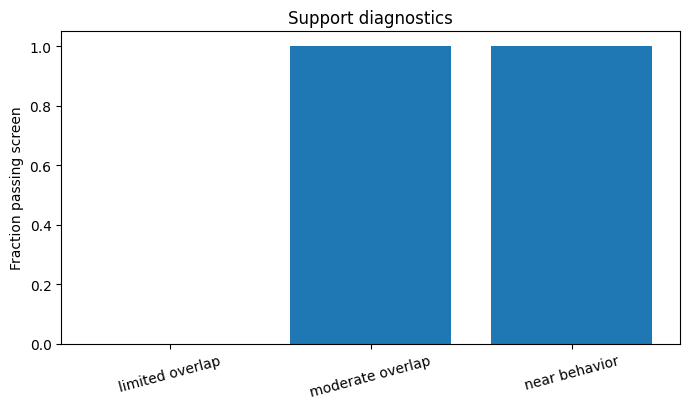

In [10]:
THRESHOLD=.10
dr=results[(results.method=="DR")&(results.interval=="normal")].copy()
dr["passes_screen"]=dr.terminal_ess_fraction>=THRESHOLD
screen=dr.groupby("scenario").apply(
 lambda g:pd.Series({"pass_fraction":g.passes_screen.mean(),
  "rmse_all":np.sqrt(np.mean(g.error**2)),
  "rmse_passed":np.sqrt(np.mean(g.loc[g.passes_screen,"error"]**2))
       if g.passes_screen.any() else np.nan,
  "coverage_passed":g.loc[g.passes_screen,"covered"].mean()
       if g.passes_screen.any() else np.nan,
  "n_passed":int(g.passes_screen.sum())}),include_groups=False).reset_index()
display(screen.round(4))
screen.to_csv(TAB/"support_screen.csv",index=False)
fig,ax=plt.subplots(figsize=(7,4.2))
ax.bar(screen.scenario,screen.pass_fraction)
ax.set(ylabel="Fraction passing screen",ylim=(0,1.05),
       title="Support diagnostics")
ax.tick_params(axis="x",rotation=15)
fig.tight_layout();fig.savefig(FIG/"support_screen.png",dpi=160);plt.show()


## Policy comparison

We compare the target policy with the logging policy using exact values.

The estimated difference is based on paired evaluation of the same logged episodes.

Exact target minus logging value: 2.9493
Difference RMSE: 0.0906
95% interval coverage: 0.975
Positive evidence: 40 | negative evidence: 0 | inconclusive: 0


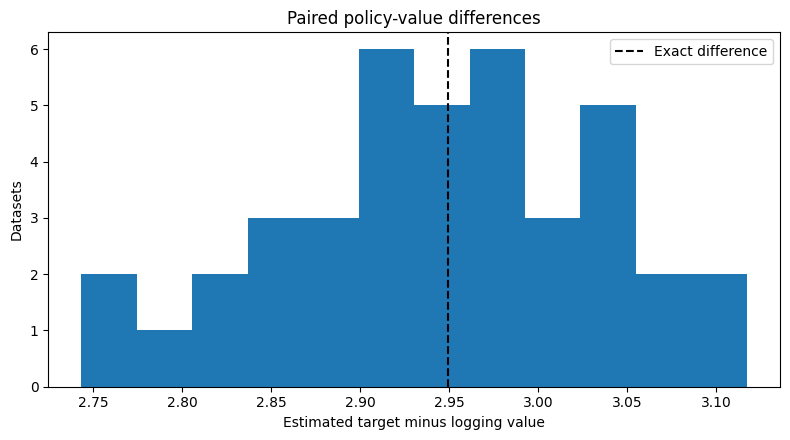

In [11]:
COMPARE_REPS=40
comparisons=[]
bpi=behavior
true_delta=exact_value(target)-exact_value(behavior)
for rep in range(COMPARE_REPS):
    st,ac,rw=simulate(N,bpi,SEED+400000+rep)
    target_parts,_=estimate(st,ac,rw,bpi,target,folds=3)
    base_parts,_=estimate(st,ac,rw,bpi,bpi,folds=3)
    diff=target_parts["DR"]-base_parts["DR"]
    lo,hi=intervals(diff,np.random.default_rng(SEED+rep))["normal"]
    comparisons.append({"rep":rep,"true_difference":true_delta,
        "estimated_difference":diff.mean(),"lower":lo,"upper":hi,
        "covered":lo<=true_delta<=hi,
        "positive_evidence":lo>0,"negative_evidence":hi<0})
comparison=pd.DataFrame(comparisons)
comparison.to_csv(TAB/"paired_policy_comparison.csv",index=False)
print("Exact target minus logging value:",round(true_delta,4))
print("Difference RMSE:",round(np.sqrt(np.mean((comparison.estimated_difference-true_delta)**2)),4))
print("95% interval coverage:",round(comparison.covered.mean(),3))
print("Positive evidence:",int(comparison.positive_evidence.sum()),
      "| negative evidence:",int(comparison.negative_evidence.sum()),
      "| inconclusive:",int((~comparison.positive_evidence&~comparison.negative_evidence).sum()))
fig,ax=plt.subplots(figsize=(8,4.5))
ax.hist(comparison.estimated_difference,bins=12)
ax.axvline(true_delta,color="black",linestyle="--",label="Exact difference")
ax.set(xlabel="Estimated target minus logging value",ylabel="Datasets",
       title="Paired policy-value differences")
ax.legend();fig.tight_layout();fig.savefig(FIG/"policy_comparison.png",dpi=160);plt.show()


## Saved experiments

The checks confirm the number of repetitions and finite estimates.

All figures, tables and settings are saved for reproducibility.

In [12]:
assert np.allclose(P.sum(axis=2),1)
assert len(results)==len(scenarios)*REPS*3*2
assert np.isfinite(results[["estimate","error","lower","upper"]].to_numpy()).all()
assert (results.upper>=results.lower).all()
metadata={"seed":SEED,"horizon":H,"discount":GAMMA,"states":S,
 "episodes_per_dataset":N,"repetitions":REPS,"bootstrap_draws":400,
 "sensitivity_repetitions":SENS_REPS,"comparison_repetitions":COMPARE_REPS,
 "interval_methods":["normal","episode contribution percentile bootstrap"],
 "note":"Bootstrap holds nuisance fits fixed; nominal coverage is empirical, not guaranteed.",
 "support_threshold":THRESHOLD,"jax_version":jax.__version__}
(TAB/"experiment_metadata.json").write_text(json.dumps(metadata,indent=2))
print("Checks passed | figures:",len(list(FIG.glob("*.png"))),
      "| reports:",len(list(TAB.iterdir())))


Checks passed | figures: 5 | reports: 7
